# Adult Income

## Câu 8. Cây quyết định CART

### Yêu cầu

Thực hiện như câu 7 với cây CART, criterion="gini".

### Dữ liệu và phương pháp

Thuộc tính quyết định: income. Sử dụng toàn bộ dữ liệu được cung cấp. Giữ nguyên nguồn train/test sau khi loại dòng trống; nối hai tập để thực hiện quy trình của đề. Tương quan cao được quy ước là |r| ≥ 0,8 giữa các thuộc tính đầu vào; giữ cột đứng trước trong thứ tự gốc. Chỉ số được trình bày theo từng lớp; precision/recall không xác định do mẫu số bằng 0 được quy ước bằng 0 và nêu rõ các lớp không được dự đoán.

In [8]:
print("Đặng Ngọc Hiếu - 6451071024")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "datasets").is_dir():
    if (ROOT / "6451071024_Lab2" / "datasets").is_dir():
        ROOT = ROOT / "6451071024_Lab2"
        break
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Không tìm thấy thư mục datasets của LAB2.")
    ROOT = ROOT.parent
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", font="DejaVu Sans")


train_raw = pd.read_csv(ROOT / "datasets/adult/adult.data.csv", skipinitialspace=True)
test_raw = pd.read_csv(ROOT / "datasets/adult/adult.test.csv", skipinitialspace=True)
if "income" not in train_raw or "income" not in test_raw:
    raise ValueError("Hai tệp Adult phải có cột income.")
if "fnlwgt" not in train_raw or "fnlwgt" in test_raw:
    raise ValueError("Kiểm tra hai phiên bản Adult: fnlwgt chỉ có trong tập huấn luyện.")


Đặng Ngọc Hiếu - 6451071024


In [9]:
print("Đặng Ngọc Hiếu - 6451071024")

# Kiểu string tường minh giúp nhận diện thiếu mà không dựa vào downcasting.
def clean_adult(frame):
    frame = frame.copy()
    for column in frame.select_dtypes(include=["object", "string"]).columns:
        values = frame[column].astype("string").str.strip()
        frame[column] = values.mask(values.isin(["?", ""]))
    return frame.dropna()

train = clean_adult(train_raw).drop(columns="fnlwgt")
test = clean_adult(test_raw)
if list(train.columns) != list(test.columns):
    raise ValueError("Tên và thứ tự cột Adult chưa khớp sau khi bỏ fnlwgt.")
n_train = len(train)
data = pd.concat([train, test], ignore_index=True)
TARGET = "income"


Đặng Ngọc Hiếu - 6451071024


In [10]:
print("Đặng Ngọc Hiếu - 6451071024")

# Tái hiện bước chọn thuộc tính của câu 3, không vẽ lại heatmap.
corr = data.drop(columns=TARGET).select_dtypes(include="number").corr(method="pearson")
CORRELATION_THRESHOLD = 0.8
# |r| >= 0,8 là quy ước đã nêu trong phương pháp, không phải ngưỡng đề ấn định.
drop_columns = []
for j, column in enumerate(corr.columns):
    for previous in corr.columns[:j]:
        value = corr.loc[previous, column]
        if previous not in drop_columns and pd.notna(value) and abs(value) >= CORRELATION_THRESHOLD:
            drop_columns.append(column)
            break
data = data.drop(columns=drop_columns)


Đặng Ngọc Hiếu - 6451071024


In [11]:
print("Đặng Ngọc Hiếu - 6451071024")

features = data.drop(columns=TARGET)
labels = data[TARGET]


Đặng Ngọc Hiếu - 6451071024


In [12]:
print("Đặng Ngọc Hiếu - 6451071024")

non_numeric = features.select_dtypes(exclude=["number", "bool"]).columns.tolist()
# uint8 lưu đúng 0/1 với một byte cho mỗi phần tử one-hot.
features_onehot = pd.get_dummies(features, columns=non_numeric, dtype="uint8")


Đặng Ngọc Hiếu - 6451071024


In [13]:
print("Đặng Ngọc Hiếu - 6451071024")

# Giữ đúng ranh giới của hai tệp Adult sau làm sạch.
X_train = features_onehot.iloc[:n_train]
X_test = features_onehot.iloc[n_train:]
y_train = labels.iloc[:n_train]
y_test = labels.iloc[n_train:]

if X_train.empty or X_test.empty:
    raise ValueError("Tập huấn luyện và kiểm thử không được trống.")


Đặng Ngọc Hiếu - 6451071024


Đặng Ngọc Hiếu - 6451071024
Accuracy: 0.8122841965471448
              precision    recall  f1-score   support

       <=50K     0.8715    0.8811    0.8763     11360
        >50K     0.6221    0.6011    0.6114      3700

    accuracy                         0.8123     15060
   macro avg     0.7468    0.7411    0.7438     15060
weighted avg     0.8102    0.8123    0.8112     15060



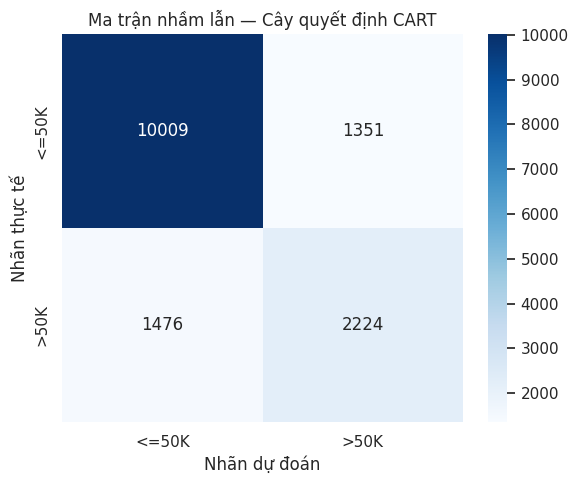

,sample_id,thuc_te,du_doan
0,30162,<=50K,<=50K
1,30163,<=50K,<=50K
2,30164,>50K,>50K
3,30165,>50K,>50K
4,30166,<=50K,<=50K
5,30167,>50K,<=50K
6,30168,<=50K,<=50K
7,30169,<=50K,<=50K
8,30170,>50K,>50K
9,30171,<=50K,<=50K


In [14]:
print("Đặng Ngọc Hiếu - 6451071024")

from sklearn.tree import DecisionTreeClassifier, plot_tree
model = DecisionTreeClassifier(criterion="gini", random_state=0)
model.fit(X_train, y_train)
predicted = model.predict(X_test)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
classes = np.unique(np.concatenate([y_train.to_numpy(), y_test.to_numpy()]))
print("Accuracy:", accuracy_score(y_test, predicted))
print(classification_report(y_test, predicted, labels=classes,
    digits=4, zero_division=0))
# Nêu rõ trường hợp chỉ số precision bằng 0 vì lớp không được dự đoán.
missing_predictions = np.setdiff1d(classes, np.unique(predicted))
if len(missing_predictions):
    print("Các lớp không có dự đoán; precision quy ước bằng 0:", missing_predictions)
cm = confusion_matrix(y_test, predicted, labels=classes)
plt.figure(figsize=(max(6,len(classes)), max(5,len(classes)*0.8)))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title("Ma trận nhầm lẫn — Cây quyết định CART")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.tight_layout()
plt.show()
plt.close()
output = ROOT / "Bai_2_Adult_Income/outputs"
output.mkdir(exist_ok=True)
predictions = pd.DataFrame({"sample_id":y_test.index, "thuc_te":y_test.to_numpy(), "du_doan":predicted})
display(predictions.head(10))
# Lưu đầy đủ dự đoán để câu 10 so sánh, tránh huấn luyện lại mô hình.
predictions.to_csv(output / "Cau08_du_doan.csv", index=False)


Đặng Ngọc Hiếu - 6451071024


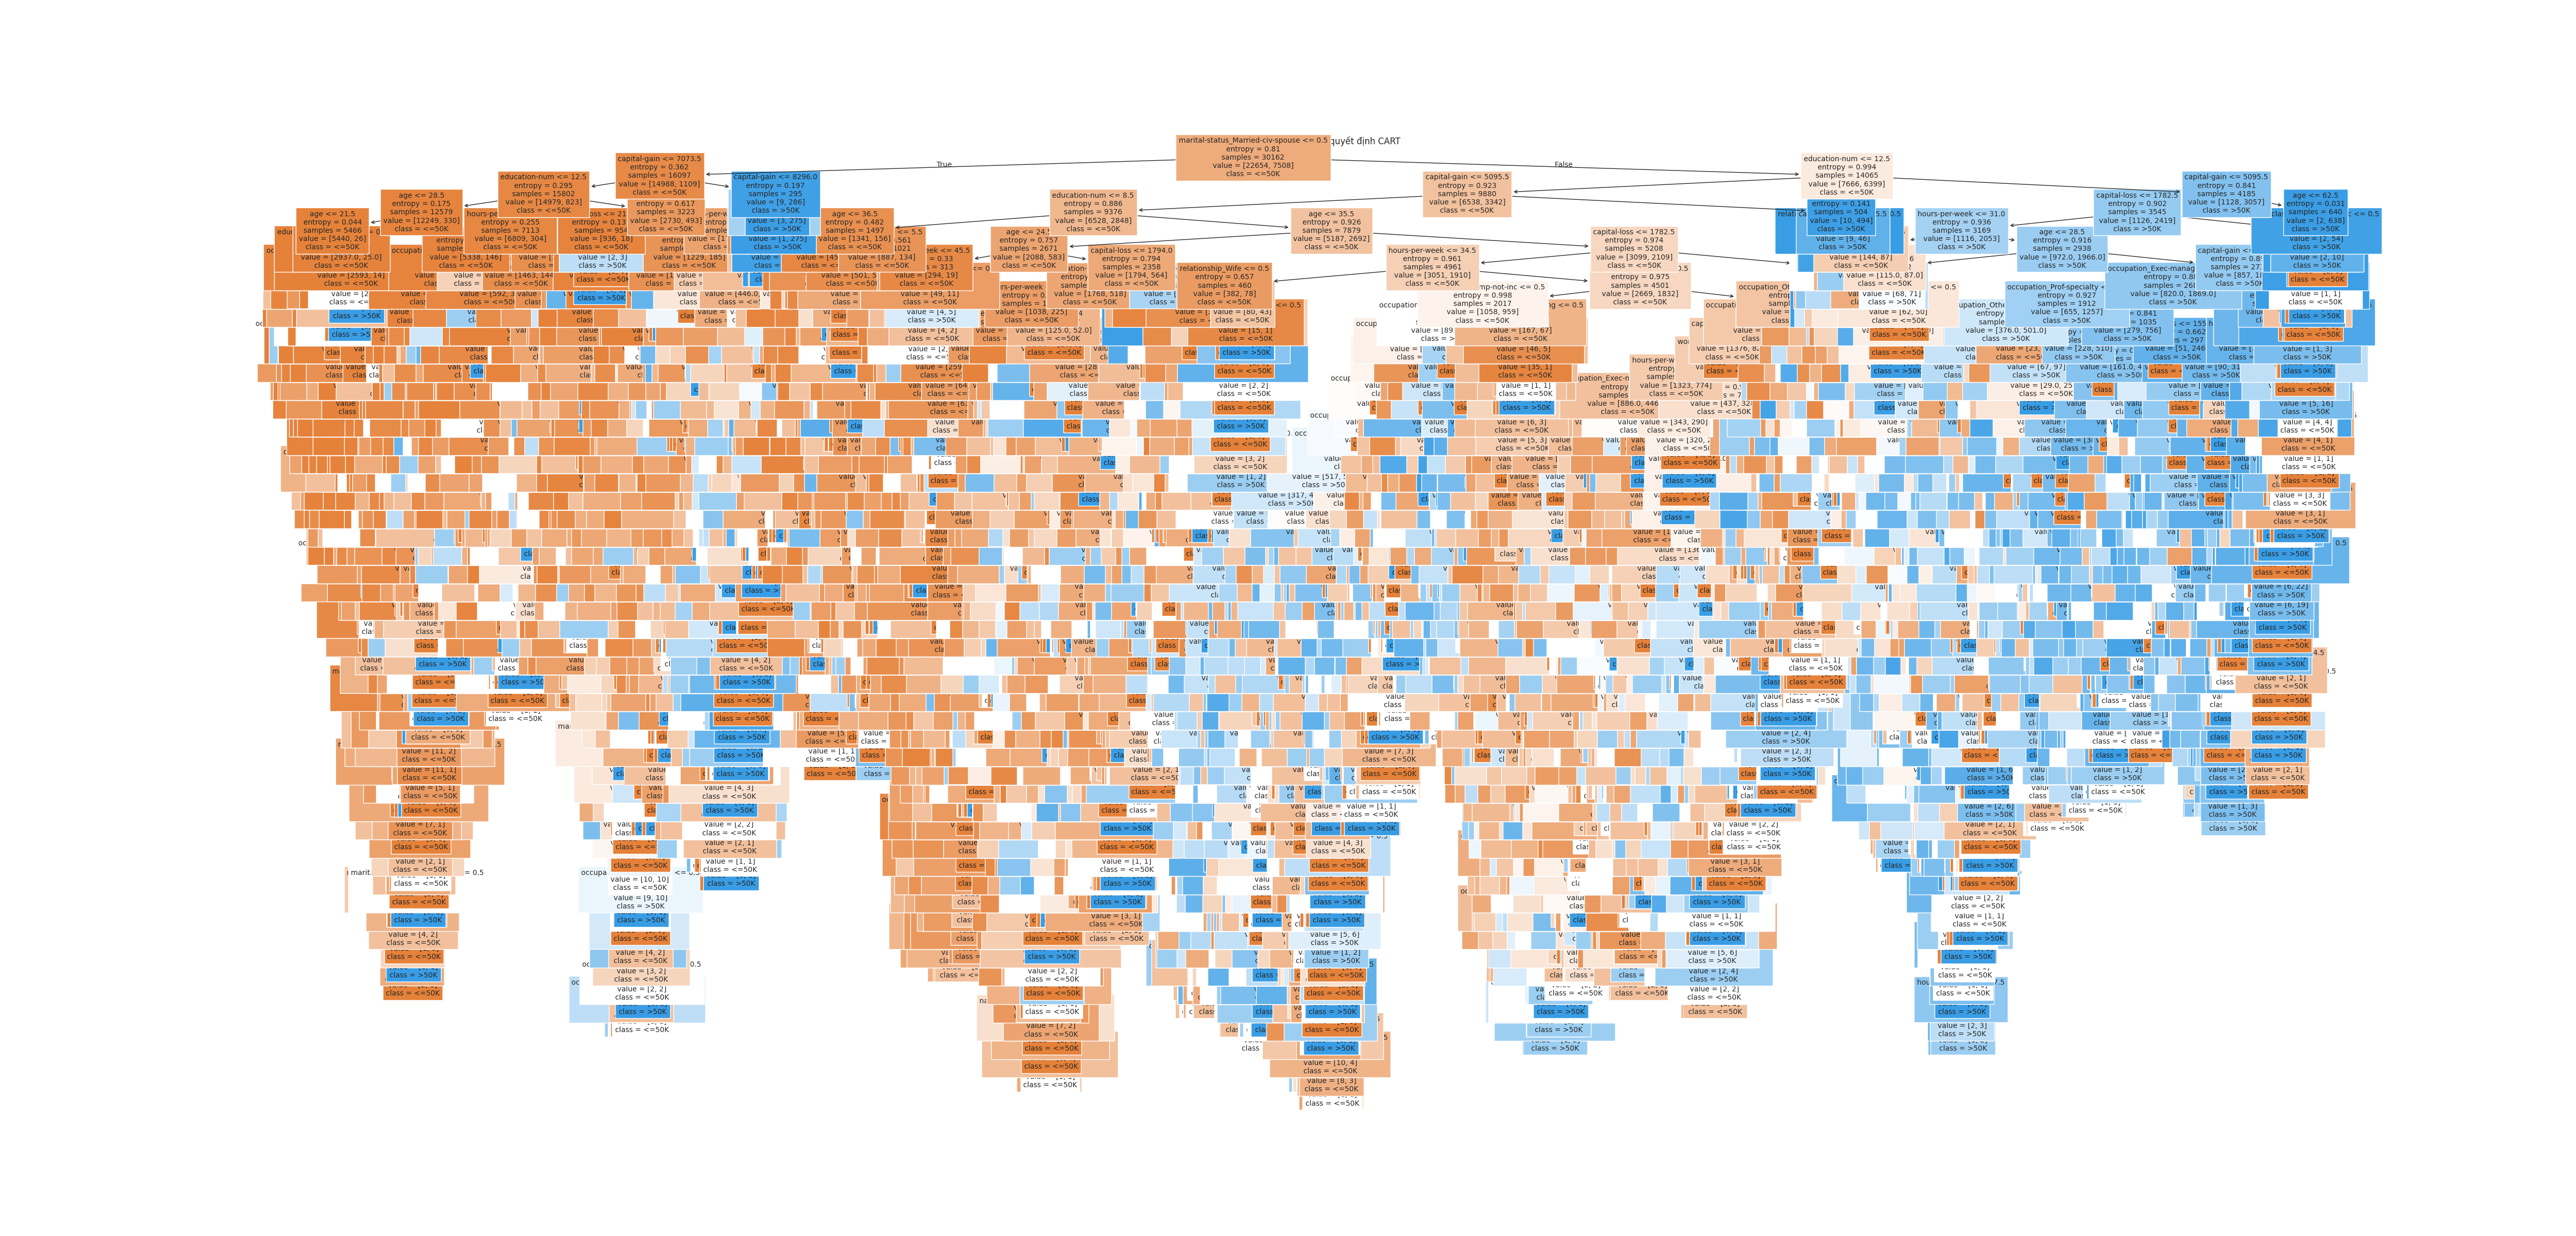

Độ sâu của cây: 51
Số nút lá: 5327


In [16]:
print("Đặng Ngọc Hiếu - 6451071024")

# Biểu diễn toàn bộ cây, không đặt giới hạn độ sâu hay cắt nhánh.
fig, ax = plt.subplots(figsize=(50, 24))
plot_tree(model, feature_names=X_train.columns.tolist(),
    class_names=[str(value) for value in model.classes_], filled=True, fontsize=10, ax=ax)
ax.set_title("Adult Income — Cây quyết định CART")
tree_path = output / "Cau08_cay_quyet_dinh.png"
fig.savefig(tree_path, dpi=100)
plt.close(fig)
# Hiển thị PNG đã lưu, tránh dựng lại toàn bộ cây để hiển thị lần thứ hai.
from IPython.display import Image as NotebookImage
display(NotebookImage(filename=str(tree_path)))
print("Độ sâu của cây:", model.get_depth())
print("Số nút lá:", model.get_n_leaves())
